In [17]:
def solution(arr):
    biggest = max(arr)
    answer = biggest
   
    # while True:
    #     flag = True
    #     for num in arr:
    #         if answer % num != 0:
    #             flag = False
    #             break
    #     if flag:
    #         return answer
    #     answer += biggest
    while True:
        if all(answer % num == 0 for num in arr):
            return answer
        answer += biggest
        
arr = [2,6,8,14]
# arr1= [1,2,3]
solution(arr)
# solution(arr1)
    
                


168

In [19]:
def solution(people, limit):
    answer = 0
    people = sorted(people)

    min_i = 0
    max_i = len(people) -1

    while min_i <= max_i:
        if people[min_i] + people[max_i] <= limit:
            min_i += 1
        max_i -= 1
        answer += 1
    return answer

people = [70, 50, 80, 50]
limit = 240
solution(people,limit)

2

In [29]:
w1, w2, lr = 0.3, 0.2, 0.01
# Inputs (x1, x2) pairs and target labels
X1 = [0.8, 0.6, 0.1, 0.3, 0.6, 0.4, 0.1]
X2 = [0.6, 0.9, 0.2, 0.1, 0.6, 0.3, 0.2]
Y  = [1, 1, 0, 0, 1, 0, 0]          # answer = labels

def step(s):
    return 1 if s >= 0.5 else 0

for epoch in range(1, 31):
    wrong = 0
    for x1, x2, y in zip(X1, X2, Y):
        s = x1 * w1 + x2 * w2
        y_pred = step(s)
        error = y - y_pred
        w1 = w1 + x1 * error * lr
        w2 = w2 + x2 * error * lr
        wrong += abs(error)
    if wrong == 0:
        break

# Check predictions
preds = [step(x1*w1 + x2*w2) for x1, x2 in zip(X1, X2)]
print("predictions:", preds)
print("converged at epoch", epoch, "| match:", preds == Y)

predictions: [1, 1, 0, 0, 1, 0, 0]
converged at epoch 17 | match: True


In [30]:
x = [1, 2, 3, 4]
y = [3, 5, 7, 9] # y = 2x + 1

w, b = 0.0, 0.0
lr = 0.01
n = len(x)

for epoch in range(5000):
    y_pre = [w * xi + b for xi in x]
    error = [yp - yi for yp, yi in zip(y_pre, y)]

    # w 변화량
    # Loss = 1/n sum(error ^2)

    dw = 2 * sum(e * xi for e, xi in zip(error , x)) /n
    db = 2 * sum(error)/n

    w -= lr * dw
    b -= lr * db
    # print(w,b)

print(w,b)
print(error)

2.000000030059674 0.999999911620893
[-5.849456030659894e-08, -2.8344619984466135e-08, 1.8053203376666715e-09, 3.195525977162106e-08]


In [39]:
import math
# ---------------------- 데이터셋 --------------------------------
# x1, x2 : 입력값, y : 정답 (1 = 비, 0 = 맑음)
X = [(0.8, 0.6), (0.6,0.9), (0.1,0.2), (0.3,0.1), (0.6,0.6), (0.4,0.3), (0.1,0.2)]
Y = [1, 1, 0, 0, 1, 0, 0] 

# ---------------------- 초기값  ---------------------------------
w1, w2 = 0.3, 0.2   # 영상과 같은 초기 연결 강도
b = -0.5
lr = 0.01           # 학습률
n = len(X)

MAX_EPOCH = 30      # 최대 반복 횟수(데이터 전체를 한 바퀴 = 1 epoch)

def sigmoid(z):
    """시그모이드"""
    return 1/(1+ math.exp(-z))

# ---------------------- 학습 과정을 한 단계씩 내보내는 함수  ---------------------------------

def train_steps():
    global w1, w2, b
    for epoch in range(1, MAX_EPOCH +1):

        p = [sigmoid(x1 * w1 + x2 * w2 + b) for x1, x2 in X]
        error = [pi - yi for pi, yi in zip(p, Y)]

        # 인자 바꿔서 활용
        dw1 = 2 * sum(e * x1 for e, (x1, x2) in zip(error, X))/n
        dw2 = 2 * sum(e * x2 for e, (x1, x2) in zip(error, X))/n
        db = 2 * sum(error)/n

        w1 -= lr * dw1
        w2 -= lr * dw2
        b -= lr * db

        
        print(f'{epoch}: {w1}, {w2}, error : {error}')
#[sigmoid(x1 * w1 + x2 * w2 + b) for x1, x2 in X]
train_steps()

1: 0.3020303136169825, 0.20230882808306233, error : [-0.5349429451582145, -0.5349429451582145, 0.3941263315682394, 0.40371730070321216, -0.5498339973124778, 0.42067574785125056, 0.3941263315682394]
2: 0.30405568051054505, 0.2046125639993571, error : [-0.5341891253753348, -0.5341178132406822, 0.3942899172282547, 0.4039243907895662, -0.549184504287081, 0.42104744346880557, 0.3942899172282547]
3: 0.30607612921791266, 0.20691123655147087, error : [-0.5334391235828728, -0.5332966028873127, 0.39445102606930976, 0.40412887857050006, -0.5485385530169609, 0.42141619011296577, 0.39445102606930976]
4: 0.30809168812300386, 0.20920487438892416, error : [-0.5326929200900747, -0.5324792950381081, 0.3946096739188292, 0.40433078043869064, -0.5478961245329499, 0.42178200529353016, 0.3946096739188292]
5: 0.3101023854566085, 0.21149350600831418, error : [-0.5319504952113298, -0.5316658706145634, 0.39476587653789935, 0.4045301127200035, -0.5472571998880111, 0.4221449064634853, 0.39476587653789935]
6: 0.312

## 합성곱 오토인코더 (ConvAutoencoder)

In [41]:
import torch
import torch.nn as nn

# [개념] ConvAE = 이미지를 "압축했다가 다시 복원"하는 합성곱 신경망.
# 입력 (1, 28, 28) -> latent (64, 1, 1) -> 출력 (1, 28, 28) 로 되돌아온다.
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        # nn.Module 상속 초기화 - PyTorch 레이어 등록을 위해 반드시 필요

        # Encoder layers
        # [압축 담당] 이미지를 단계적으로 작게 줄여나감 (해상도 절반씩)
        self.encoder = nn.Sequential(
            # (1,28,28) -> (16,14,14) : 28x28 흑백 이미지를 16종류의 특징 지도로
            # stride=2 가 핵심: 커널이 2칸씩 건너뛰며 훑어서 출력이 절반 크기가 됨 = 다운샘플링
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),  # (16, 14, 14)
            # ReLU: 음수는 0으로. 비선형성 부여 + (참고) 0이 많아지는 효과도 있음
            nn.ReLU(),
            # 특징 지도를 더 깊게: (16,14,14) -> (32,7,7)  다시 절반 압축
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # (32, 7, 7)
            nn.ReLU(),
            # 마지막 압축: kernel_size=7, stride=1 이므로 7x7 -> 1x1 이 됨
            # 결과적으로 이미지 전체 정보를 "숫자 64개"로 압축 = latent space (- 안 복선)
            nn.Conv2d(32, 64, kernel_size=7)  # (64, 1, 1) - Latent space
        )

        # Decoder layers
        # [복원 담당] Encoder의 거울상. 줄어든 크기를 다시 키워나감 (ConvTranspose2d)
        self.decoder = nn.Sequential(
            # ConvTranspose2d = "역(逆) 합성곱". 작은 지도(1x1)를 퍼뜨려 크게 만듦
            # Encoder의 마지막 Conv2d(32,64,k=7)를 정확히 되돌리는 레이어: 1x1 -> 7x7
            nn.ConvTranspose2d(64, 32, kernel_size=7),  # (32, 7, 7)
            nn.ReLU(),
            # 7x7 -> 14x14. stride=2로 두 배 확대하는데, 딱 나눠떨어지도록
            # output_padding=1 로 한 칸 더 보정 (짝수 크기 맞추기용)
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),  # (16, 14, 14)
            nn.ReLU(),
            # 14x14 -> 28x28. 채널 16 -> 1 (원래 흑백 개수로 되돌림)
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),  # (1, 28, 28)
            # Sigmoid: 출력을 0~1 범위로 고정. MNIST 픽셀 값이 0(검정)~1(흰색)이므로
            # 재구성 이미지를 원본과 같은 범위로 맞추기 위한 것
            # [주의] 이건 "값 범위 조정"일 뿐, sparse(희소)와는 무관!
            nn.Sigmoid()  # Output pixel values are between 0 and 1
        )

    def forward(self, x):
        # 데이터가 흐르는 경로: 입력 -> 압축 -> 복원
        x = self.encoder(x)   # 784 픽셀 -> 64개 숫자로 압축
        x = self.decoder(x)   # 64개 숫자 -> 다시 784 픽셀로 복원
        return x              # "원본과 최대한 닮은" 복원 이미지가 출력

# 동작 검증: 랜덤 이미지를 넣어 출력 크기가 입력과 같은지 확인
model = ConvAutoencoder()
x = torch.randn(1, 1, 28, 28)
print(model(x).shape)  # torch.Size([1, 1, 28, 28])


torch.Size([1, 1, 28, 28])


## ConvAutoencoder 학습

In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader

# MNIST 데이터 준비
# ToTensor: PIL 이미지(0~255)를 Torch 텐서(0.0~1.0)로 변환 - Sigmoid 출력 범위와 일치
transform = torchvision.transforms.ToTensor()
train_data = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
# DataLoader: 데이터를 128장씩 묶어(batch) 랜덤 순서(shuffle)로 공급
# 한 번에 6만 장을 다 넣으면 메모리가 버티지 못하므로 나눠서 넣는다
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)

# Convolutional Autoencoder, Loss, Optimizer 초기화
conv_model = ConvAutoencoder()          # 위에서 정의한 모델 객체 생성
conv_criterion = nn.MSELoss()           # 손실(점수) 함수: 복원 이미지와 원본의 픽셀 차이의 제곱 평균
#                                  값이 작을수록 원본을 잘 복원한 것
conv_optimizer = optim.Adam(conv_model.parameters(), lr=0.001)
#                                  optim.Adam = 가중치를 어떤 방향/속도로 수정할지 결정하는 알고리즘
#                                  lr(learning rate)=한 번에 얼마나 크게 수정할지 (0.001 = 보수적)

# Training loop for Convolutional Autoencoder
num_epochs = 20  # Can adjust this
# 전체 6만 장 데이터셋을 20번 반복해서 본다 = 20번의 복습

print('Starting training for Convolutional Autoencoder...')

for epoch in range(num_epochs):
    total_loss = 0                      # 이번 에포크 동안의 손실 합계 저장용
    for data in train_loader:           # 배치(128장) 단위로 반복: 60000/128 ≈ 469번
        img, _ = data  # 레이블은 사용하지 않음
        # 오토인코더는 "정답 = 입력 자신". 숫자가 뭔지(레이블) 알 필요가 없다!
        # No need to flatten for Conv layers
        # 합성곱은 2D 이미지 형태 그대로 받으므로 flatten 불필요 (MLP였다면
        # img.view(-1, 784) 로 1줄로 펼쳐야 했음)

        recon = conv_model(img)         # ① 순전파: 압축 -> 복원 시도
        loss = conv_criterion(recon, img)  # ② 점수 매기기: 복원본이 원본과 얼마나 다른가

        conv_optimizer.zero_grad()      # ③ 이전 단계의 기울기 잔여분 초기화 (안 하면 누적됨)
        loss.backward()                 # ④ 역전파: "가중치를 어떻게 바꿔야 loss가 줄까" 계산
        conv_optimizer.step()           # ⑤ 가중치 실제 수정 (learning rate 반영)

        total_loss += loss.item()       # 텐서에서 숫자만 꺼내 누적

    avg_loss = total_loss / len(train_loader)  # 배치 수로 나눠 평균 = 이 에포크의 대표 점수
    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {avg_loss:.5f}')
# [흐름 요약] ①~⑤가 한 배치마다 반복되며, loss가 점점 내려가면 잘 학습되는 중


100%|██████████| 9.91M/9.91M [00:04<00:00, 2.38MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:17<00:00, 96.7kB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


Starting training for Convolutional Autoencoder...
Epoch [1/20], Loss: 0.06393
Epoch [2/20], Loss: 0.01191
Epoch [3/20], Loss: 0.00712
Epoch [4/20], Loss: 0.00546
Epoch [5/20], Loss: 0.00454
Epoch [6/20], Loss: 0.00400
Epoch [7/20], Loss: 0.00362
Epoch [8/20], Loss: 0.00336
Epoch [9/20], Loss: 0.00315
Epoch [10/20], Loss: 0.00299
Epoch [11/20], Loss: 0.00287
Epoch [12/20], Loss: 0.00276
Epoch [13/20], Loss: 0.00268
Epoch [14/20], Loss: 0.00261
Epoch [15/20], Loss: 0.00255
Epoch [16/20], Loss: 0.00250
Epoch [17/20], Loss: 0.00245
Epoch [18/20], Loss: 0.00241
Epoch [19/20], Loss: 0.00238
Epoch [20/20], Loss: 0.00235


## Variational Autoencoder (VAE)

In [46]:
# [개념] VAE(Variational AutoEncoder)
# ConvAE와 목표는 같지만, latent를 "한 점"이 아니라 "확률분포(구름)"로 압축한다.
# 덕분에 latent 공간이 연속적으로 채워져서 -> 새 이미지 "생성"이 가능해진다.
# ConvAE는 전이 합성곱 구조였지만, VAE는 그냥 완전연결층(Linear) 구조 (입력은 1차원으로 펼침)
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        # latent_dim = 압축된 코드의 길이. 여기선 20 (ConvAE의 64보다 짧아도 됨)

        self.fc1 = nn.Linear(28 * 28, 512)   # 784픽셀 -> 512 (압축 1단계)
        self.fc2_mu = nn.Linear(512, latent_dim)       # 512 -> 20: 각 차원의 "평균 mu"
        self.fc2_logvar = nn.Linear(512, latent_dim)   # 512 -> 20: 각 차원의 "분산(log)"

        # logvar 를 쓰는 이유: 분산은 항상 양수여야 하는데,
        # log 를 씌워두면 값이 -~+ 자유롭게 나와도 exp() 하면 양수가 됨 (학습이 안정적)

        self.fc3 = nn.Linear(latent_dim, 512)  # 복원 1단계: 20 -> 512
        self.fc4 = nn.Linear(512, 28 * 28)     # 복원 2단계: 512 -> 784 (원본 크기)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()  # 출력 픽셀을 0~1로 (MNIST 픽셀 범위)

    def encode(self, x):
        # 이미지 -> (mu, logvar) 두 개의 코드를 동시에 반환
        # "이 이미지의 압축 코드는 평균 mu 근처, 분산 logvar 만큼 퍼져 있다"
        h1 = self.relu(self.fc1(x))
        return self.fc2_mu(h1), self.fc2_logvar(h1)

    def reparameterize(self, mu, logvar):
        # [VAE의 핵심 트릭] 재파라미터화(reparameterization)
        # "mu 근처에서 무작위로 한 점을 샘플링" 하는 연산.
        std = torch.exp(0.5 * logvar)    # log 분산 -> 표준편차 복원 (exp(0.5*logvar) = sqrt(var))
        eps = torch.randn_like(std)      # 표준정규분포 잡음 (학습 때마다 다른 값!)
        return mu + eps * std            # 최종 코드 z = 평균 + 잡음*크기
        # 왜 이렇게 우회하냐: "분포에서 뽑기"는 미분이 불가해 학습이 안 되지만,
        # "고정된 mu/std 에 무작위 eps 를 곱해 더하기"는 미분 가능 -> 학습 가능!
        # 매번 살짝 다른 z 로도 복원되야 하므로, latent 공간에 빈 구멍이 생기지 않음

    def decode(self, z):
        # 압축 코드 z -> 784픽셀 이미지로 복원 (Encoder의 반대 경로)
        h3 = self.relu(self.fc3(z))
        return self.sigmoid(self.fc4(h3))

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, 28 * 28))  # 이미지를 1차원으로 펼쳐서 인코딩
        z = self.reparameterize(mu, logvar)            # 분포에서 코드 한 점 샘플링
        return self.decode(z), mu, logvar              # (복원이미지, 평균, 분산) 3개 반환
        # mu, logvar 를 밖으로 꺼내는 이유: loss 계산에 필요하기 때문

# VAE Loss Function
def vae_loss_function(recon_x, x, mu, logvar):
    # VAE 손실 = 복원 품질 점수 + 분포 정리 점수, 두 개의 합!
    BCE = nn.functional.binary_cross_entropy(recon_x, x.view(-1, 28 * 28), reduction='sum')
    # BCE: 복원 이미지가 원본 픽셀과 얼마나 다른가 (0~1 값을 다루므로 BCE 사용)
    #      reduction='sum': 픽셀별 오차를 다 더함 (.dtd 큰 숫자로 나옴)
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    # KLD(Kullback-Leibler Divergence): 인코더가 만든 분포(mu, logvar)가
    #   "표준정규분포(평균0, 분산1)"에서 얼마나 벗어났는가의 측정값
    # 이 항이 있기에 latent 공간 전체가 정리되어 채워짐 -> 새 코드를 뽑아도 진짜같은 이미지!
    # mu=0, logvar=0 (분산=1) 이 되면 KLD=0 이 되도록 밀어붙인다
    return BCE + KLD
    # 두 항은 서로 길항: BCE만 chargé 남으면 분포 엉망(생성 불가), KLD만 세면 흐릿한 복원.
    # 학습은 이 균형점을 찾아가는 과정

# initialize VAE
latent_dim = 20  # you can adjust the latent dimension
vae_model = VAE(latent_dim)  # 모델 생성 (ConvAE 때와 동일하게)
vae_optimizer = optim.Adam(vae_model.parameters(), lr=0.001)

# Training loop for VAE
num_epochs = 20  # can adjust this

print('Starting training for Variational Autoencoder...')

for epoch in range(num_epochs):
    vae_model.train()   # 학습 모드 ON (dropout 등 사용 시 동작 차이, 여기선 형식적)
    train_loss = 0      # 에포크 전체 손실 누적
    for batch_idx, (data, _) in enumerate(train_loader):
        # enumerate: 몇 번째 배치인지(batch_idx)도 같이 줌 (안 쓰면 _ 처리해도 됨)

        vae_optimizer.zero_grad()        # ③ 기울기 초기화
        recon_batch, mu, logvar = vae_model(data)  # ① 순전파: 세 개 값 반환
        loss = vae_loss_function(recon_batch, data, mu, logvar)  # ② BCE+KLD 계산
        loss.backward()                  # ④ 역전파
        train_loss += loss.item()        # 손실 누적
        vae_optimizer.step()             # ⑤ 가중치 갱신

    # 데이터셋 전체 크기(6만)로 나눔: 샘플 1개당 평균 손실 (sum reduction이므로 이렇게 나눠야 비교 가능)
    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {train_loss / len(train_loader.dataset):.4f}')


Starting training for Variational Autoencoder...
Epoch [1/20], Loss: 159.6773
Epoch [2/20], Loss: 119.5865
Epoch [3/20], Loss: 113.2457
Epoch [4/20], Loss: 110.5549
Epoch [5/20], Loss: 108.9311
Epoch [6/20], Loss: 107.8901
Epoch [7/20], Loss: 107.1389
Epoch [8/20], Loss: 106.5192
Epoch [9/20], Loss: 106.0430
Epoch [10/20], Loss: 105.6568
Epoch [11/20], Loss: 105.3277
Epoch [12/20], Loss: 105.0647
Epoch [13/20], Loss: 104.8440
Epoch [14/20], Loss: 104.5678
Epoch [15/20], Loss: 104.3636
Epoch [16/20], Loss: 104.1791
Epoch [17/20], Loss: 103.9963
Epoch [18/20], Loss: 103.8089
Epoch [19/20], Loss: 103.6499
Epoch [20/20], Loss: 103.5453


## 재구성 결과 시각화 (Original vs ConvAE vs VAE)

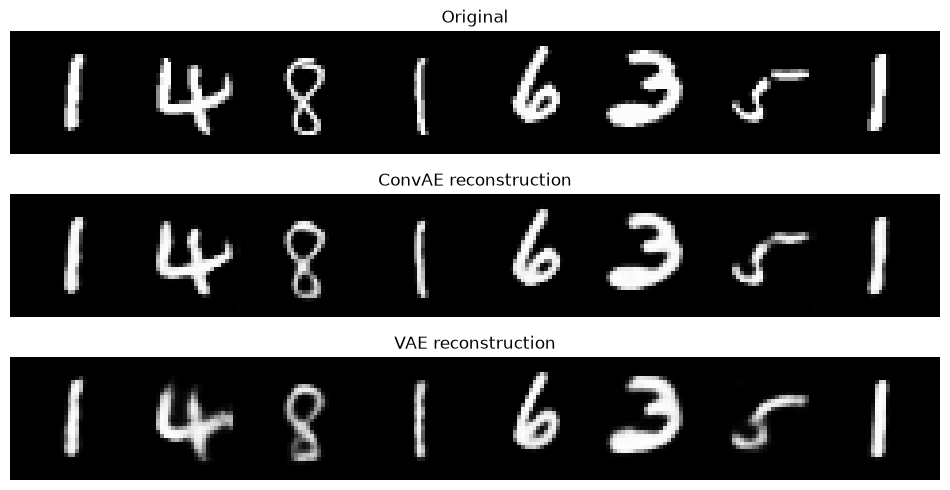

In [49]:
import torchvision
import matplotlib.pyplot as plt

# [목표] 학습 때 본 적 없는 테스트 이미지로 두 모델의 복원 실력 비교
test_data = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_data, batch_size=8, shuffle=True)

images, labels = next(iter(test_loader))  # 테스트 숫자 8장 (원본 = 답안지)

conv_model.eval()   # 평가 모드: 학습 전용 동작(kwargs dropout 등) 끄기
vae_model.eval()

with torch.no_grad():  # 평가 때는 기울기 계산 불필요 -> 메모리/속도 절약
    recon_conv = conv_model(images)        # ConvAE 복원 시도 (출력: (8,1,28,28))
    recon_vae, _, _ = vae_model(images)    # VAE 복원 시도 (출력: (8,784) 2D!)
    # 두 모델 출력 shape가 다름! VAE는 Linear 구조라 2D (8장 x 784픽셀)

def show_row(row, title, ax):
    # 여러 이미지를 한 줄로 이어붙여 그리는 헬퍼 함수
    grid = torchvision.utils.make_grid(row, nrow=8, padding=2)
    # make_grid: 이미지 배치를 격자 형태의 한 장의 큰 이미지로 합침
    ax.imshow(grid.permute(1, 2, 0).squeeze())
    # permute: PyTorch는 (채널,높이,너비), matplotlib은 (높이,너비,채널) 순서라 뒤집기 필요
    ax.set_title(title)
    ax.axis('off')  # 좌표 눈금 제거 - 이미지만 보기

fig, axes = plt.subplots(3, 1, figsize=(12, 6))  # 3행짜리 비교표 만들기
show_row(images, 'Original', axes[0])            # 1행: 원본 (정답)
show_row(recon_conv, 'ConvAE reconstruction', axes[1])  # 2행: ConvAE가 그린 그림
show_row(recon_vae.view(-1, 1, 28, 28), 'VAE reconstruction', axes[2])
#                                     ^ VAE 출력(2D)을 이미지 그리드 형식(4D)으로 reshape!
#                                       이게 없으면 make_grid가 shape를 잘못 해석해
#                                       "가로로 눌린 빵빵한 이미지"가 나왔었음
plt.show()
# [판독법] 원본과 얼마나 비슷한가를 눈으로 비교.
# VAE가 살짝 흐릿한 건 정상: KLD 항 때문에 latent가 뭉개지는 대가


## VAE latent sampling & 보간 (VAE만 가능한 기능)

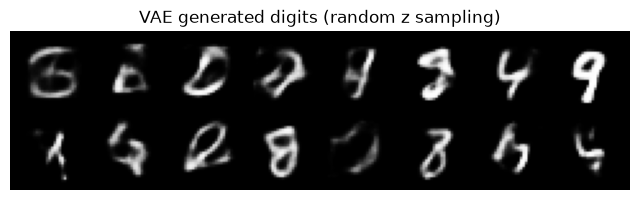

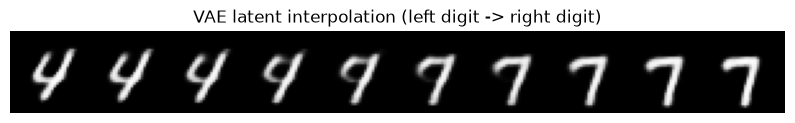

In [50]:
# [개념] VAE만 가능한 두 가지 마법: (1)새 숫자 생성 (2)두 숫자 사이 모핑
# ConvAE는 latent 공간에 "빈 구멍"이 많아서 이게 불가능. VAE는 KLD 덕에 공간이 꽉 차 있음.

# --- (1) 무작위 생성 ---
# VAE latent space sampling: 무작위 z -> decoder로 새 숫자 생성
with torch.no_grad():
    z = torch.randn(16, latent_dim)        # 표준정규분포에서 코드 z 16개를 "주사위로 뽑기"
    # VAE 학습 시 KLD가 z 공간을 표준정규분포 형태로 정리해놨기 때문에,
    # randn 으로 뽑은 z 는 거의 항상 "진짜 숫자가 사는 동네" 좌표이다!
    samples = vae_model.decode(z)          # 뽑은 코드로 이미지 생성 (존재한 적 없는 새 숫자!)

grid = torchvision.utils.make_grid(samples.view(-1, 1, 28, 28), nrow=8, padding=2)
plt.figure(figsize=(8, 4))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap='gray')
plt.title('VAE generated digits (random z sampling)')
plt.axis('off')
plt.show()

# --- (2) 보간(interpolation) = 두 숫자 사이를 걸어가기 ---
# latent space를 연속적으로 이동: 두 숫자 사이 보간(interpolation)
test_iter = iter(DataLoader(test_data, batch_size=2, shuffle=True))
x1, x2 = next(test_iter)[0][0:2]   # 서로 다른 두 숫자 이미지 (예: "3"과 "7")

with torch.no_grad():
    mu1, _ = vae_model.encode(x1.view(-1, 28 * 28))   # 첫 숫자의 "지도상 위치"
    mu2, _ = vae_model.encode(x2.view(-1, 28 * 28))   # 둘째 숫자의 "지도상 위치"

    alphas = [i / 9 for i in range(10)]   # 0.0, 0.11, 0.22, ..., 1.0 : 이동 비율 10단계
    interp = []
    for a in alphas:
        z = mu1 + a * (mu2 - mu1)     # 두 위치를 선형으로 섞기 (a=0이면 mu1, a=1이면 mu2)
        interp.append(vae_model.decode(z).view(1, 28, 28))  # 섞은 위치에서 이미지 그리기

# 왼쪽(a=0) -> 오른쪽(a=1)로 갈수록 첫 숫자가 서서히 둘째 숫자로 변신
# 중간 단계가 "의미 있는 애매한 숫자"로 보이면 latent 공간이 연속적이라는 증거
grid = torchvision.utils.make_grid(torch.cat(interp).view(-1, 1, 28, 28), nrow=10, padding=2)
#                                     ^ interp 10장(각 (1,28,28))을 4D 배치로 reshape
#                                       없으면 (10,28,28)을 3D 이미지로 오해해 shape 에러!
plt.figure(figsize=(10, 2))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap='gray')
plt.title('VAE latent interpolation (left digit -> right digit)')
plt.axis('off')
plt.show()
# [실험 아이디어] mu 끼리 섞는 대신 reparameterize 로 샘플 z 끼리 섞으면
# 흔들리는 생성 경로가 보인다 - VAE가 "확률적"이라는 것을 체감할 수 있음


# 이미지 불러오기

In [53]:
from PIL import Image

content_img = Image.open('1.jpg')
style_img = Image.open('norway.jpg')


# 전처리

In [59]:
import torch
from torchvision import transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

# VGG19가 학습될 때 쓰던 ImageNet 평균/표준편차로 정규화해야 feature가 정확히 나옴
img_transform = transforms.Compose([
    transforms.Resize((400, 400)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

content = img_transform(content_img)[:3, :, :].unsqueeze(0).to(device)  # RGBA 등 알파 채널 제거 + 배치 차원
style = img_transform(style_img)[:3, :, :].unsqueeze(0).to(device)
print('content:', content.shape, '| style:', style.shape)


device: cuda
content: torch.Size([1, 3, 400, 400]) | style: torch.Size([1, 3, 400, 400])


# 복원

In [61]:
import numpy as np

def im_convert(tensor):
    """정규화된 텐서(B,3,H,W) -> 화면에 표시 가능한 numpy 이미지(0~1)로 복원"""
    image = tensor.to('cpu').clone().detach()   # 학습 상태와 분리된 사본 확보
    image = image.numpy().squeeze()             # (1,3,H,W) -> (3,H,W)
    image = image.transpose(1, 2, 0)            # (3,H,W) -> (H,W,3)
    image = image * np.array((0.229, 0.224, 0.225)) + np.array((0.485, 0.456, 0.406))  # 정규화 반대 연산
    image = image.clip(0, 1)
    return image


# VGG 로딩 & 특징 추출 (get_features)

In [62]:
import torch.nn as nn
import torchvision.models as models

# VGG19 features 로딩: torchvision의 사전학습 가중치 사용
vgg = models.vgg19(pretrained=True).features.to(device).eval()  # eval: dropout/BN 비활성
for param in vgg.parameters():
    param.requires_grad_(False)   # VGG는 학습 대상이 아님. 최적화는 target 이미지 픽셀!

def get_features(image, model, layers=None):
    """image를 VGG에 순전파하며 지정 계층의 출력(특징맵)을 딕셔너리로 저장"""
    if layers is None:
        layers = {'0': 'conv1_1', '5': 'conv2_1', '10': 'conv3_1',
                  '19': 'conv4_1', '21': 'conv4_2', '28': 'conv5_1'}
    features = {}
    x = image
    for name, layer in model._modules.items():
        x = layer(x)
        if name in layers:
            features[layers[name]] = x
        if name == '28':
            break
    return features

def gram_matrix(tensor):
    """특징맵(B,d,h,w) -> GRAM 행렬(d,d). 채널 간 상관 = 스타일(질감) 정보"""
    _, d, h, w = tensor.shape
    t = tensor.view(d, h * w)          # 채널별로 벡터화
    return torch.mm(t, t.t())          # (d,hw) @ (hw,d) = (d,d)

# 컨텐츠 특징: 원본 이미지를 VGG에 한 번만 통과 (학습 내내 재사용)
content_features = get_features(content, vgg)
# 스타일 특징: 원본 스타일 이미지의 각 계층별 GRAM 행렬 (학습 내내 재사용)
style_features = get_features(style, vgg)
style_grams = {layer: gram_matrix(f) for layer, f in style_features.items()
               if layer != 'conv4_2'}   # conv4_2는 컨텐츠용 계층이라 스타일엔 제외
print('feature layers:', list(content_features.keys()))


feature layers: ['conv1_1', 'conv2_1', 'conv3_1', 'conv4_1', 'conv4_2', 'conv5_1']


step    1 | content: 0.0000 | style: 546.586426 | total: 5465864192.0000
step  400 | content: 7.8090 | style: 122.839264 | total: 1228392576.0000
step  800 | content: 9.6373 | style: 64.108742 | total: 641087424.0000
step 1200 | content: 10.6902 | style: 38.927288 | total: 389272896.0000
step 1600 | content: 11.4471 | style: 25.890129 | total: 258901312.0000
step 2000 | content: 12.0231 | style: 18.240416 | total: 182404176.0000
step 2400 | content: 12.4436 | style: 13.370610 | total: 133706120.0000
step 2800 | content: 12.7750 | style: 10.069253 | total: 100692544.0000
step 3200 | content: 13.0380 | style: 7.738048 | total: 77380488.0000
step 3600 | content: 13.2631 | style: 6.037358 | total: 60373592.0000
step 4000 | content: 13.4546 | style: 4.756927 | total: 47569276.0000
step 4400 | content: 13.6408 | style: 3.770749 | total: 37707500.0000
step 4800 | content: 13.8141 | style: 2.998944 | total: 29989456.0000


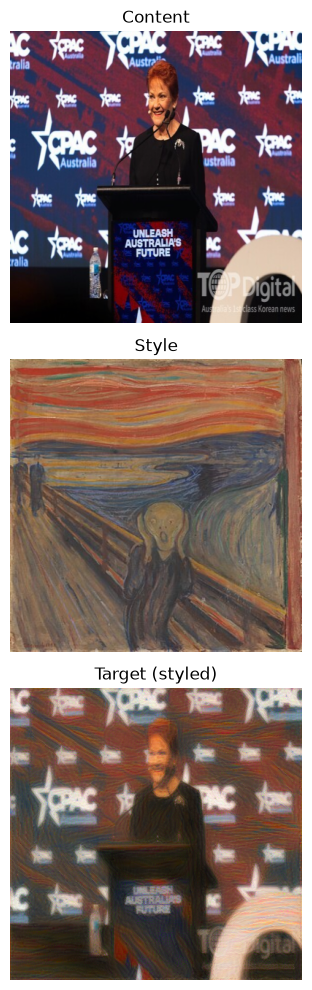

In [64]:
import torch.optim as optim

# 1) 가중치: 스타일 계층별 중요도 (얕은 계층 = 색/질감, 깊은 계층 = 큰 질감)
style_weights = {'conv1_1': 1., 'conv2_1': 0.75, 'conv3_1': 0.2, 'conv4_1': 0.2, 'conv5_1': 0.2}
content_weight = 1    # alpha: 컨텐츠(모양)를 얼마나 유지할지
style_weight = 1e7    # beta : 스타일(질감) 강도. 컨텐츠보다 수백만 배 크게!

# 2) 최적화 대상 = VGG 가중치가 아니라 "이미지 픽셀 자체". requires_grad=True가 핵심
target = content.clone().requires_grad_(True).to(device)

optimizer = optim.Adam([target], lr=0.001)
steps = 5000
show_every = 400      # 중간 결과 출력 주기

for ii in range(1, steps + 1):
    target_features = get_features(target, vgg)

    # --- 컨텐츠 loss: conv4_2에서 원본과의 차이 ---
    content_loss = torch.mean((target_features['conv4_2'] - content_features['conv4_2']) ** 2)

    # --- 스타일 loss: 각 계층의 GRAM 차이 ---
    style_loss = 0
    for layer in style_weights:
        tf = target_features[layer]
        target_gram = gram_matrix(tf)
        _, d, h, w = tf.shape
        layer_style_loss = style_weights[layer] * torch.mean((target_gram - style_grams[layer]) ** 2)
        style_loss += layer_style_loss / (d * h * w)

    total_loss = content_weight * content_loss + style_weight * style_loss

    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()

    if ii % show_every == 0 or ii == 1:
        print(f'step {ii:4d} | content: {content_loss.item():.4f} | style: {style_loss.item():.6f} | total: {total_loss.item():.4f}')

# 3) 최종 결과 확인
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
axes[0].imshow(im_convert(content));  axes[0].set_title('Content');  axes[0].axis('off')
axes[1].imshow(im_convert(style));    axes[1].set_title('Style');    axes[1].axis('off')
axes[2].imshow(im_convert(target));   axes[2].set_title('Target (styled)'); axes[2].axis('off')
plt.tight_layout()
plt.show()


https://github.com/shangeth/Neural-Style-Transfer/blob/master/neural_style_transfer.ipynb